# 05 — Feature engineering evaluation (v3)
So sánh feature sets bằng cùng Stratified 5-fold trên 70% development train. Giữ 15% validation cho NB06 và 15% holdout cho NB07. Đây là split theo ID từ pipeline cũ, không chứng minh ID là thời gian. Holdout đã từng được xem ở phase trước nên không phải test hoàn toàn độc lập.

Dùng tham số champion cố định, không early stopping trên fold đánh giá. AP là mặc định; đổi `PRIMARY_METRIC` thành `ROC-AUC` nếu đó là metric chính thức. AI scam flag chỉ bật sau audit availability/leakage.

In [1]:
from pathlib import Path
import sys, json, pickle
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import lightgbm as lgb
import xgboost as xgb
from sklearn.model_selection import StratifiedKFold
from sklearn.metrics import average_precision_score, roc_auc_score, brier_score_loss

PROJECT_ROOT = Path.cwd().resolve()
if not (PROJECT_ROOT / "src").is_dir():
    PROJECT_ROOT = PROJECT_ROOT.parent
assert (PROJECT_ROOT / "src").is_dir(), "Run from project root or notebooks/"
sys.path.insert(0, str(PROJECT_ROOT))
from src.features import add_features, FEATURE_VERSION, FEATURE_SETS, CATEGORICAL_COLUMNS
from src.config import PRIMARY_METRIC as PRIMARY_METRIC_KEY, SECONDARY_METRIC as SECONDARY_METRIC_KEY, METRIC_LABELS, OUTPUT_VERSION
from src.split import time_based_split, create_stratified_kfold
assert FEATURE_VERSION == "v3", "Copy features_v3.py to src/features.py and restart kernel"
DATA_DIR = PROJECT_ROOT / "data"
ARTIFACT_DIR = DATA_DIR / "artifacts"
ARTIFACT_DIR.mkdir(parents=True, exist_ok=True)
RANDOM_STATE = 42
N_SPLITS = 5
N_JOBS = 4
# Use "cuda:0" on a machine with a compatible XGBoost GPU setup.
XGB_DEVICE = "cpu"

In [2]:
def load_featured(kind):
    raw_path = DATA_DIR / f"{kind}.csv"
    cache_path = DATA_DIR / f"{kind}_featured_{FEATURE_VERSION}.pkl"
    required = set(FEATURE_SETS["compact_all"]) | {"id"}
    identity_cols = ["id", "is_fraud"] if kind == "train" else ["id"]
    required.update(identity_cols)
    if cache_path.exists() and cache_path.stat().st_mtime >= raw_path.stat().st_mtime:
        try:
            frame = pd.read_pickle(cache_path)
            identity = pd.read_csv(raw_path, usecols=identity_cols)
            if not required.issubset(frame.columns):
                raise ValueError("Missing v3 features")
            for col in identity_cols:
                if not np.array_equal(frame[col].to_numpy(), identity[col].to_numpy()):
                    raise ValueError(f"Cached {col} alignment mismatch")
            if not frame["id"].is_unique:
                raise ValueError("Duplicate IDs")
            print("Loaded:", cache_path.name)
            return frame.reset_index(drop=True)
        except (OSError, ImportError, AttributeError, TypeError, ValueError,
                NotImplementedError, EOFError, pickle.UnpicklingError) as exc:
            print(f"Rebuilding {cache_path.name}: {exc}")
    raw = pd.read_csv(raw_path)
    frame = add_features(raw.drop(columns="is_fraud", errors="ignore"))
    if kind == "train":
        frame["is_fraud"] = raw["is_fraud"].astype(int)
    assert frame["id"].is_unique and required.issubset(frame.columns)
    frame.to_pickle(cache_path)
    print("Saved:", cache_path.name)
    return frame.reset_index(drop=True)


def align_categories(train, *others, cat_cols):
    train = train.copy()
    others = [frame.copy() for frame in others]
    for col in cat_cols:
        # Materialize strings to ensure XGBoost-compatible categorical labels.
        train[col] = train[col].astype(object).astype("category").cat.remove_unused_categories()
        cats = train[col].cat.categories
        for frame in others:
            frame[col] = pd.Categorical(frame[col].astype(object), categories=cats)
    return (train, *others)


def split_development(frame):
    parts = time_based_split(frame, id_col="id", train_ratio=0.70,
                             valid_ratio=0.15, buffer_size=0)
    return tuple(parts[k].sort_values("id").reset_index(drop=True)
                 for k in ("train", "valid", "test_holdout"))


def scores(y, p):
    return {"AP": float(average_precision_score(y, p)),
            "ROC-AUC": float(roc_auc_score(y, p)),
            "Brier": float(brier_score_loss(y, p))}


def fixed_params(config):
    out = {"LightGBM": dict(config["lightgbm_params"]),
           "XGBoost": dict(config["xgboost_params"])}
    for params in out.values():
        params.pop("early_stopping_rounds", None)
        params.pop("callbacks", None)
        params["n_jobs"] = N_JOBS
    out["XGBoost"].update(device=XGB_DEVICE, enable_categorical=True, tree_method="hist")
    return out


def build_model(name, params):
    return (lgb.LGBMClassifier if name == "LightGBM" else xgb.XGBClassifier)(**params)

In [3]:
PRIMARY_METRIC = METRIC_LABELS[PRIMARY_METRIC_KEY]
SECONDARY_METRIC = METRIC_LABELS[SECONDARY_METRIC_KEY]
assert PRIMARY_METRIC == "ROC-AUC" and SECONDARY_METRIC == "AP"
ALLOW_AI_FLAG = False
EXPERIMENTS = ["raw_legacy", "raw_core", "compact_legacy", "category_auth",
               "binary_risk", "cvv_risk", "auth_risk", "transaction_risk", "compact_all"]
if ALLOW_AI_FLAG:
    EXPERIMENTS += ["raw_all", "compact_all_with_ai"]
champion_path = ARTIFACT_DIR / "final_model_config.json"
if not champion_path.exists():
    raise FileNotFoundError("Keep the old champion final_model_config.json for fixed-parameter ablation")
champion_config = json.loads(champion_path.read_text(encoding="utf-8"))
params = fixed_params(champion_config)
ALPHA = 0.58  # fixed champion blend; do not optimize per feature set
all_df = load_featured("train")
train_df, valid_df, holdout_df = split_development(all_df)
y = train_df["is_fraud"].to_numpy(dtype=int)
fold_indices = list(StratifiedKFold(n_splits=N_SPLITS, shuffle=True,
                                   random_state=RANDOM_STATE).split(train_df, y))
fold_ids = np.full(len(y), -1, dtype=int)
for f, (_, va) in enumerate(fold_indices):
    fold_ids[va] = f
assert (fold_ids >= 0).all()
print("Development/validation/holdout:", len(train_df), len(valid_df), len(holdout_df))
display(pd.DataFrame({"feature_set": EXPERIMENTS,
                      "n_features": [len(FEATURE_SETS[s]) for s in EXPERIMENTS]}))

Loaded: train_featured_v3.pkl
Development/validation/holdout: 489971 104995 104994


,feature_set,n_features
0,raw_legacy,18
1,raw_core,23
2,compact_legacy,27
3,category_auth,28
4,binary_risk,31
5,cvv_risk,31
6,auth_risk,32
7,transaction_risk,30
8,compact_all,42


## Fixed-parameter ablation
Mỗi nhóm chạy 5 fold × 2 model; lưu AP, ROC-AUC, Brier theo fold và pooled OOF. So sánh các nhóm với `compact_legacy` (cùng 27 cột nền), không dùng holdout để chọn.

In [4]:
rows, fold_rows, oof_store = [], [], {}
for fs_name in EXPERIMENTS:
    cols = list(FEATURE_SETS[fs_name])
    assert len(cols) == len(set(cols)) and set(cols).issubset(train_df.columns)
    cats = [c for c in cols if c in CATEGORICAL_COLUMNS]
    X = train_df[cols]
    oof = {name: np.full(len(y), np.nan) for name in ("LightGBM", "XGBoost", "Weighted Blending")}
    for fold, (tr, va) in enumerate(fold_indices):
        X_tr, X_va = align_categories(X.iloc[tr], X.iloc[va], cat_cols=cats)
        for name in ("LightGBM", "XGBoost"):
            model = build_model(name, params[name])
            model.fit(X_tr, y[tr])
            oof[name][va] = model.predict_proba(X_va)[:, 1]
        oof["Weighted Blending"][va] = ALPHA * oof["LightGBM"][va] + (1-ALPHA) * oof["XGBoost"][va]
        for name, p in oof.items():
            fold_rows.append({"feature_set": fs_name, "model": name, "fold": fold,
                              **scores(y[va], p[va])})
        print(fs_name, "fold", fold, scores(y[va], oof["Weighted Blending"][va]))
    for name, p in oof.items():
        assert np.isfinite(p).all()
        matching_folds = [r for r in fold_rows if r["feature_set"] == fs_name and r["model"] == name]
        per_fold_roc_auc = [r["ROC-AUC"] for r in matching_folds]
        per_fold_ap = [r["AP"] for r in matching_folds]
        rows.append({"feature_set": fs_name, "model": name, "n_features": len(cols),
                     **scores(y, p),
                     "mean_cv_roc_auc": np.mean(per_fold_roc_auc), "std_cv_roc_auc": np.std(per_fold_roc_auc),
                     "mean_cv_ap": np.mean(per_fold_ap), "std_cv_ap": np.std(per_fold_ap)})
        oof_store[f"{fs_name}__{name}"] = p
results = pd.DataFrame(rows)
fold_results = pd.DataFrame(fold_rows)
results.to_csv(ARTIFACT_DIR / f"05_ablation_results_{OUTPUT_VERSION}.csv", index=False)
fold_results.to_csv(ARTIFACT_DIR / f"05_ablation_folds_{OUTPUT_VERSION}.csv", index=False)
np.savez_compressed(ARTIFACT_DIR / f"05_oof_{OUTPUT_VERSION}.npz", ids=train_df.id.astype(str).to_numpy(dtype=str),
                    y=y, folds=fold_ids, **oof_store)
display(results.sort_values(PRIMARY_METRIC, ascending=False))

raw_legacy fold 0 {'AP': 0.3561796103173339, 'ROC-AUC': 0.9160104518688373, 'Brier': 0.013155334147661232}
raw_legacy fold 1 {'AP': 0.36704415228628195, 'ROC-AUC': 0.9152160414859954, 'Brier': 0.012990626865036933}
raw_legacy fold 2 {'AP': 0.3454464060337835, 'ROC-AUC': 0.908002740527214, 'Brier': 0.013327487815484833}
raw_legacy fold 3 {'AP': 0.36207987431701627, 'ROC-AUC': 0.9160579202405408, 'Brier': 0.013056792632727588}
raw_legacy fold 4 {'AP': 0.36254119577982796, 'ROC-AUC': 0.9187434698194762, 'Brier': 0.013046097989933201}
raw_core fold 0 {'AP': 0.5000261461170054, 'ROC-AUC': 0.9475957364449943, 'Brier': 0.011371568846466677}
raw_core fold 1 {'AP': 0.503694693864041, 'ROC-AUC': 0.9443607021940945, 'Brier': 0.011277914605037092}
raw_core fold 2 {'AP': 0.4955675866431609, 'ROC-AUC': 0.9419912271588303, 'Brier': 0.011329731209196824}
raw_core fold 3 {'AP': 0.4983074400862079, 'ROC-AUC': 0.9455775883300056, 'Brier': 0.011300369111805311}
raw_core fold 4 {'AP': 0.5191365000534821, '

,feature_set,model,n_features,AP,ROC-AUC,Brier,mean_cv_roc_auc,std_cv_roc_auc,mean_cv_ap,std_cv_ap
5,raw_core,Weighted Blending,23,0.503104,0.945186,0.011260,0.945198,0.001923,0.503346,0.008323
14,binary_risk,Weighted Blending,31,0.503390,0.945180,0.011263,0.945202,0.001910,0.503577,0.008413
20,auth_risk,Weighted Blending,32,0.503418,0.945085,0.011262,0.945100,0.001953,0.503602,0.009149
13,binary_risk,XGBoost,31,0.503076,0.945080,0.011565,0.945099,0.001918,0.503273,0.008487
4,raw_core,XGBoost,23,0.502370,0.945075,0.011560,0.945086,0.001931,0.502541,0.008873
8,compact_legacy,Weighted Blending,27,0.502371,0.945062,0.011266,0.945074,0.001755,0.502538,0.008948
17,cvv_risk,Weighted Blending,31,0.503312,0.945049,0.011268,0.945068,0.001834,0.503432,0.007732
23,transaction_risk,Weighted Blending,30,0.502087,0.945044,0.011270,0.945053,0.001705,0.502234,0.008432
7,compact_legacy,XGBoost,27,0.501783,0.945002,0.011561,0.945013,0.001763,0.502006,0.009548
16,cvv_risk,XGBoost,31,0.502201,0.944961,0.011591,0.944976,0.001788,0.502250,0.007899


,feature_set,n_features,ROC-AUC,mean_cv_roc_auc,AP,mean_cv_ap,rank_roc_auc,rank_ap,rank_delta_ap_minus_roc_auc
5,raw_core,23,0.945186,0.945198,0.503104,0.503346,1,4,3
14,binary_risk,31,0.945180,0.945202,0.503390,0.503577,2,2,0
20,auth_risk,32,0.945085,0.945100,0.503418,0.503602,3,1,-2
8,compact_legacy,27,0.945062,0.945074,0.502371,0.502538,4,5,1
17,cvv_risk,31,0.945049,0.945068,0.503312,0.503432,5,3,-2
23,transaction_risk,30,0.945044,0.945053,0.502087,0.502234,6,6,0
11,category_auth,28,0.943812,0.943826,0.495890,0.496098,7,8,1
26,compact_all,42,0.943775,0.943792,0.497530,0.497728,8,7,-1
2,raw_legacy,18,0.914776,0.914806,0.358023,0.358658,9,9,0


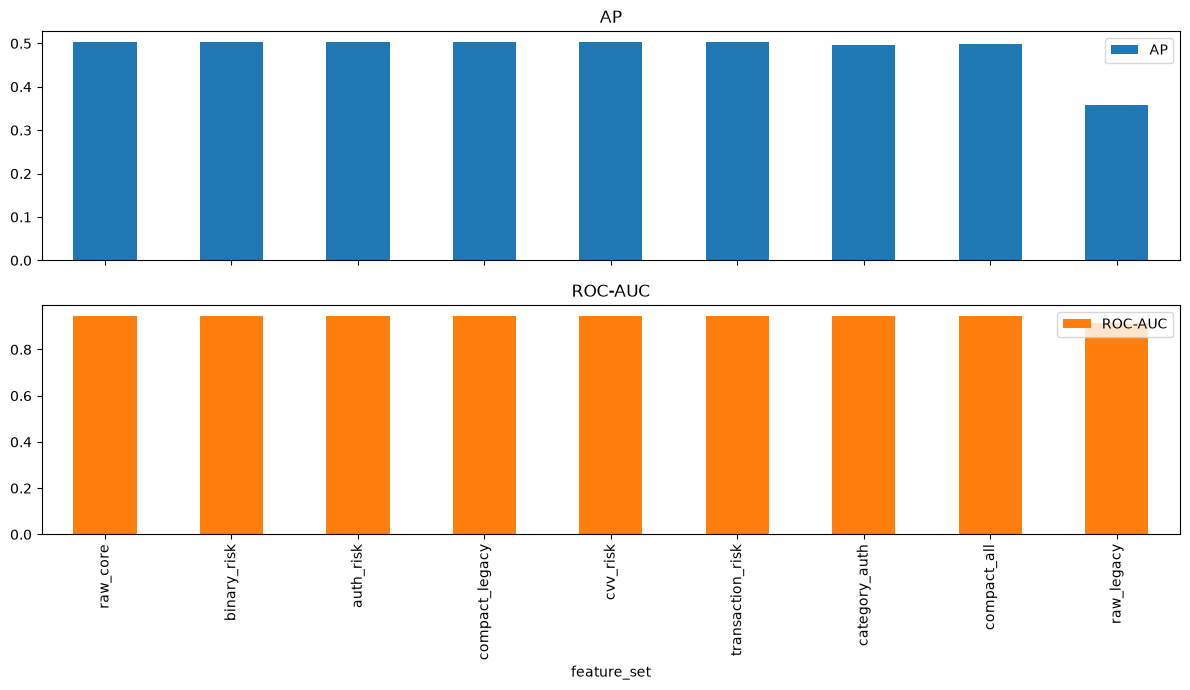

Selected: raw_core | Saved: D:\Project\FraudDetection\data\artifacts\05_feature_selection_v4.json


In [5]:
ensemble = results[results.model.eq("Weighted Blending")].copy()
ensemble = ensemble.sort_values([PRIMARY_METRIC, "mean_cv_roc_auc", "n_features"], ascending=[False, False, True])
if "compact_legacy" in ensemble.feature_set.values:
    ref = ensemble.loc[ensemble.feature_set.eq("compact_legacy"), PRIMARY_METRIC].iloc[0]
    ensemble["delta_vs_compact_legacy"] = ensemble[PRIMARY_METRIC] - ref
# Automatic default: highest pooled OOF metric; optionally select simpler near-tie after reviewing fold table.
FEATURE_SET_OVERRIDE = None
best_name = FEATURE_SET_OVERRIDE or ensemble.iloc[0]["feature_set"]
assert best_name in EXPERIMENTS
chosen = ensemble.loc[ensemble.feature_set.eq(best_name)].iloc[0]
ranking = ensemble[["feature_set", "n_features", "ROC-AUC", "mean_cv_roc_auc", "AP", "mean_cv_ap"]].copy()
ranking["rank_roc_auc"] = ranking["ROC-AUC"].rank(method="min", ascending=False).astype(int)
ranking["rank_ap"] = ranking["AP"].rank(method="min", ascending=False).astype(int)
ranking["rank_delta_ap_minus_roc_auc"] = ranking["rank_ap"] - ranking["rank_roc_auc"]
ranking = ranking.sort_values(["rank_roc_auc", "mean_cv_roc_auc", "n_features"], ascending=[True, False, True])
display(ranking)
ranking.to_csv(ARTIFACT_DIR / f"05_feature_set_metric_ranking_{OUTPUT_VERSION}.csv", index=False)
ensemble.set_index("feature_set")[["AP", "ROC-AUC"]].plot(kind="bar", subplots=True, figsize=(12, 7), sharex=True)
plt.tight_layout(); plt.show()
selection = {"feature_version": FEATURE_VERSION, "output_version": OUTPUT_VERSION, "feature_set": best_name,
             "feature_columns": FEATURE_SETS[best_name], "primary_metric": PRIMARY_METRIC, "secondary_metric": SECONDARY_METRIC,
             "n_splits": N_SPLITS, "random_state": RANDOM_STATE, "allow_ai_flag": ALLOW_AI_FLAG,
             "blend_alpha": ALPHA, "development_rows": len(y),
             "pooled_oof_scores": {"ROC-AUC": float(chosen["ROC-AUC"]), "AP": float(chosen["AP"])},
             "mean_cv_scores": {"ROC-AUC": float(chosen.mean_cv_roc_auc), "AP": float(chosen.mean_cv_ap)}}
path = ARTIFACT_DIR / f"05_feature_selection_{OUTPUT_VERSION}.json"
path.write_text(json.dumps(selection, indent=2), encoding="utf-8")
print("Selected:", best_name, "| Saved:", path)